# **TP2 : Modèles Génératifs avec PyTorch**
### **Modèle Discriminatif, Auto-encodeur Simple et Variational Autoencoder (VAE)**
**Auteur :** Iliass Mouhtad  
**Cadre :** Module d'IA Multimodale / Deep Learning — ENSET Casablanca, Université Hassan II  
**Support de référence :** `Modeles_generatifs_pytorch_avec_explications.ipynb` (Pr. Mohamed YOUSSFI)

---

### **Objectifs et Fil Pédagogique du Notebook**
Dans ce travail pratique, nous explorons les fondements des architectures d'apprentissage profond pour les données visuelles (MNIST), en suivant une progression logique allant du modèle discriminatif jusqu'aux modèles génératifs variationnels :

1. **Chargement et Préparation du Dataset MNIST :**
   - Téléchargement, normalisation des tenseurs et création des `DataLoader` PyTorch.
   - Visualisation d'échantillons avec leurs étiquettes réelles.
2. **Modèle Discriminatif (Classification supervisée) :**
   - Apprentissage de la distribution conditionnelle $P(y|x)$.
   - Conception d'un classifieur dense (MLP) avec `CrossEntropyLoss`.
   - Entraînement et évaluation (Accuracy globale sur le jeu de test).
   - Analyse critique : pourquoi ce modèle ne sait pas générer de nouvelles images.
3. **Auto-encodeur Simple (Autoencoder - AE) :**
   - Apprentissage non supervisé : compression dans un espace latent $z \in \mathbb{R}^2$ et reconstruction $\hat{x} \approx x$.
   - Fonction de perte MSE de reconstruction.
   - Visualisation des reconstructions et projection de l'espace latent 2D (clusters par chiffre).
   - Synthèse conditionnelle par barycentre (centroïde) de classe.
   - Limites de l'AE classique : espace latent non régularisé, zones vides et échec de la génération aléatoire.
4. **Variational Autoencoder (VAE) :**
   - Formalisme probabiliste : approximation variationnelle $q_\phi(z|x)$ et a priori $p(z) \sim \mathcal{N}(0, I)$.
   - Le *Reparameterization Trick* ($z = \mu + \sigma \odot \epsilon$) pour permettre la rétropropagation.
   - Fonction de coût ELBO : perte de reconstruction (BCE) + divergence de Kullback-Leibler (KL).
   - Entraînement et suivi des pertes (`Total`, `Reconstruction`, `KL Divergence`).
   - Évaluation de la fidélité de reconstruction.
   - Visualisation de l'espace latent régularisé et centré en $(0,0)$.
   - Génération de nouveaux chiffres réalistes ex nihilo à partir de bruit gaussien standard.
   - Exploration continue de l'espace latent via une grille 2D (variété continue).
   - Interpolation linéaire latente (morphing continu entre deux chiffres).
5. **Synthèse Comparative Finale :** Tableau récapitulatif des 3 paradigmes.


## **0. Préparation de l'environnement & Configuration du matériel**

Nous importons les bibliothèques indispensables :
- `torch` et `torch.nn` : calcul tensoriel, différentiation automatique et modules de réseaux de neurones.
- `torchvision` : jeux de données et transformations pour la vision par ordinateur.
- `matplotlib.pyplot` : visualisations graphiques et affichage des images.
- `numpy` : calcul scientifique et manipulation de grilles.

Nous vérifions également la disponibilité de l'accélération matérielle (GPU CUDA ou CPU) et fixons une graine aléatoire pour la reproductibilité.


In [1]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# Reproductibilité des résultats
torch.manual_seed(42)
np.random.seed(42)

print("Version PyTorch :", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Périphérique d'exécution :", device)


Version PyTorch : 2.14.1+cpu
Périphérique d'exécution : cpu


# **Partie 1 : Chargement et Inspection du Dataset MNIST**

### **Présentation des données**
Le jeu de données **MNIST** (*Modified National Institute of Standards and Technology*) est composé de **70 000 images** en niveaux de gris de chiffres manuscrits (de 0 à 9) :
- **60 000 images** pour l'entraînement (`train_dataset`).
- **10 000 images** pour le test (`test_dataset`).
- Chaque image a une résolution de $28 \times 28$ pixels, soit un total de $784$ pixels par image.

### **Transformation : `transforms.ToTensor()`**
La transformation `transforms.ToTensor()` réalise deux opérations essentielles :
1. Conversion de l'image en tenseur PyTorch de dimensions `(C, H, W) = (1, 28, 28)`.
2. Normalisation des valeurs de pixels de l'intervalle entier $[0, 255]$ vers l'intervalle réel $[0.0, 1.0]$.


In [2]:
# Détection du dossier data (compatible exécution depuis tp2/ ou la racine)
data_dir = "./data" if os.path.exists("./data") else "../data"

# Transformation
transform = transforms.ToTensor()

# Chargement du jeu d'entraînement et de test
train_dataset = datasets.MNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root=data_dir,
    train=False,
    download=True,
    transform=transform
)

# Création des DataLoaders par mini-lots de 128 images
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print(f"Nombre d'exemples d'entraînement : {len(train_dataset)}")
print(f"Nombre d'exemples de test          : {len(test_dataset)}")
print(f"Nombre de batches par époque (train): {len(train_loader)}")


Nombre d'exemples d'entraînement : 60000
Nombre d'exemples de test          : 10000
Nombre de batches par époque (train): 469


### **Visualisation d'un échantillon d'images MNIST**
Visualisons 10 images du lot d'entraînement avec leurs étiquettes réelles pour valider le chargement.


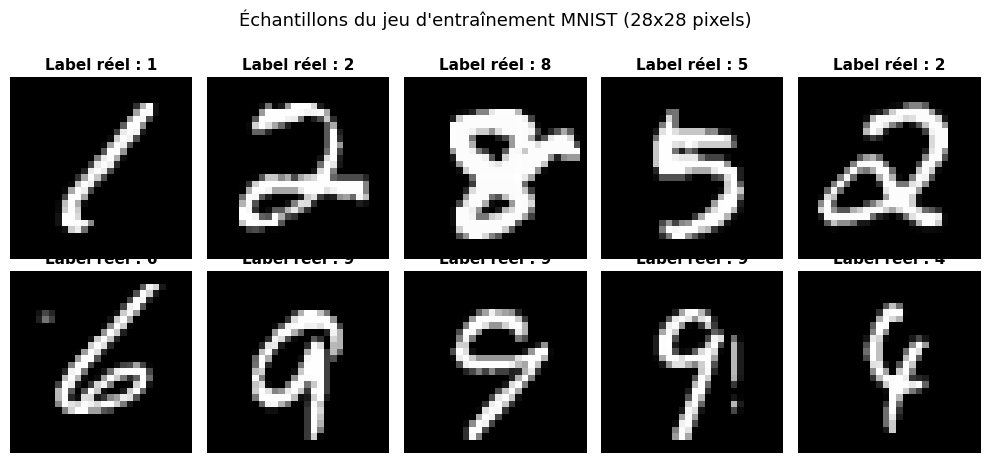

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label réel : {labels[i].item()}", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Échantillons du jeu d'entraînement MNIST (28x28 pixels)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


# **Partie 2 : Créer, Entraîner et Évaluer le Modèle Discriminatif**

### **1. Principe théorique : Apprentissage de $P(y|x)$**
Un modèle **discriminatif** reçoit en entrée une observation $x$ (ici une image de chiffre manuscrit $28 \times 28$) et cherche à prédire sa classe cible $y \in \{0, 1, \dots, 9\}$.
$$
x \xrightarrow{\text{Réseau de neurones}} \hat{y} \approx P(y|x)
$$
Le modèle apprend à tracer des frontières de décision dans l'espace des données pour séparer les 10 classes.

### **2. Architecture du Classifieur (MLP)**
- `nn.Flatten()` : aplatit chaque image de dimensions $(B, 1, 28, 28)$ en un vecteur $(B, 784)$.
- `nn.Linear(784, 128)` + `nn.ReLU()` : première couche dense de 128 neurones avec activation non linéaire.
- `nn.Linear(128, 10)` : couche de sortie produisant 10 valeurs réelles (les **logits**) pour les classes 0 à 9.

### **3. Fonction de coût et Optimisation**
- Pour la classification multi-classe, nous utilisons la perte d'entropie croisée (`nn.CrossEntropyLoss`), qui applique en interne un `LogSoftmax` suivi du `NLLLoss` (Negative Log-Likelihood) :
$$
\mathcal{L}_{\text{class}} = -\sum_{c=0}^9 y_c \log(\hat{p}_c)
$$
- L'optimiseur utilisé est **Adam** avec un taux d'apprentissage $\eta = 10^{-3}$.


In [4]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
print(classifier)

total_params = sum(p.numel() for p in classifier.parameters() if p.requires_grad)
print(f"Nombre total de paramètres entraînables : {total_params:,}")


Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Nombre total de paramètres entraînables : 101,770


### **Entraînement du Classifieur**
Nous définissons la procédure d'entraînement sur 5 époques avec suivi de la perte moyenne.


In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

def train_classifier(model, loader, epochs=5):
    model.train()
    history = []

    for epoch in range(epochs):
        total_loss = 0.0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        epoch_loss = total_loss / len(loader)
        history.append(epoch_loss)
        print(f"Époque [{epoch+1}/{epochs}] - Perte (Cross-Entropy Loss) : {epoch_loss:.4f}")

    return history

print("--- Début de l'entraînement du modèle discriminatif ---")
classifier_history = train_classifier(classifier, train_loader, epochs=5)


--- Début de l'entraînement du modèle discriminatif ---
Époque [1/5] - Perte (Cross-Entropy Loss) : 0.4115
Époque [2/5] - Perte (Cross-Entropy Loss) : 0.1943
Époque [3/5] - Perte (Cross-Entropy Loss) : 0.1374
Époque [4/5] - Perte (Cross-Entropy Loss) : 0.1059
Époque [5/5] - Perte (Cross-Entropy Loss) : 0.0852


### **Évaluation du Modèle Discriminatif sur le Jeu de Test**
Nous calculons la précision globale (*Accuracy*) sur les 10 000 images de test jamais rencontrées par le réseau.
Nous utilisons également la métrique `MulticlassAccuracy` de `torcheval` pour valider la mesure.


In [6]:
def evaluate_classifier(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            pred = logits.argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)

    accuracy = correct / total
    return accuracy

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy sur l'ensemble de test (PyTorch natif) : {100 * accuracy:.2f}%")

# Évaluation complémentaire via torcheval
try:
    from torcheval.metrics import MulticlassAccuracy
    metric = MulticlassAccuracy(device=device)
    classifier.eval()
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            logits = classifier(x)
            metric.update(logits, y)
    print(f"Accuracy via torcheval.metrics               : {100 * metric.compute().item():.2f}%")
except ImportError:
    pass


Accuracy sur l'ensemble de test (PyTorch natif) : 97.32%
Accuracy via torcheval.metrics               : 97.32%


### **Visualisation des Prédictions du Classifieur**
Affichons un lot d'images de test avec la prédiction du modèle en vert si elle est correcte, et en rouge en cas d'erreur.


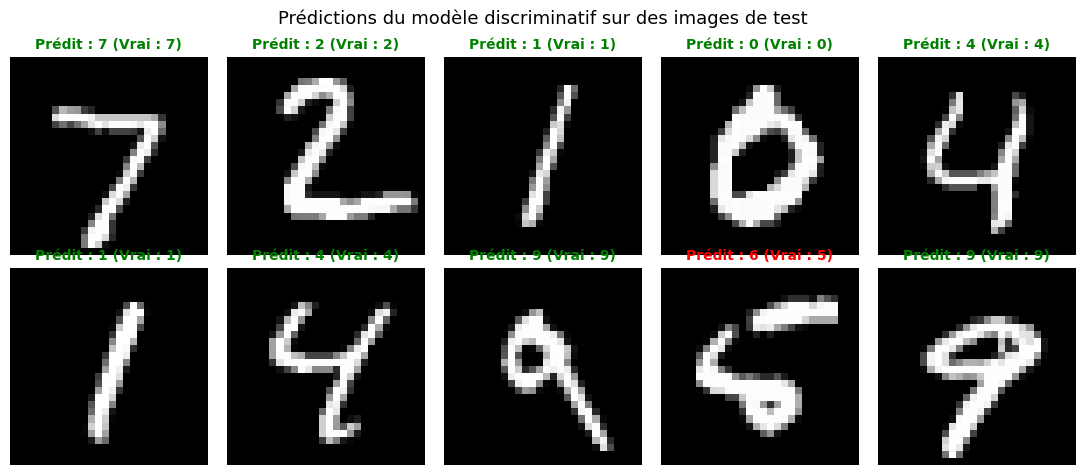

In [7]:
classifier.eval()
test_images, test_labels = next(iter(test_loader))
test_images, test_labels = test_images.to(device), test_labels.to(device)

with torch.no_grad():
    test_logits = classifier(test_images)
    test_preds = test_logits.argmax(dim=1)

fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
for i, ax in enumerate(axes.flat):
    img = test_images[i].cpu().squeeze()
    pred_lbl = test_preds[i].item()
    true_lbl = test_labels[i].item()
    color = "green" if pred_lbl == true_lbl else "red"

    ax.imshow(img, cmap="gray")
    ax.set_title(f"Prédit : {pred_lbl} (Vrai : {true_lbl})", color=color, fontweight="bold", fontsize=10)
    ax.axis("off")

plt.suptitle("Prédictions du modèle discriminatif sur des images de test", fontsize=13)
plt.tight_layout()
plt.show()


### **Bilan de la Partie 2 : Pourquoi passer aux modèles génératifs ?**
- Le modèle discriminatif apprend une frontière séparatrice $x \mapsto y$.
- Il atteint une précision remarquable (~97.5% sur MNIST).
- **Cependant, il ne modélise pas la distribution $P(x)$ des images.** Il est incapable de générer un chiffre manuscrit ou de comprendre la structure interne des données.
- Pour **générer de nouvelles données** et explorer l'espace des chiffres, nous devons nous tourner vers les **modèles non supervisés et génératifs** : l'auto-encodeur simple puis le VAE.


# **Partie 3 : Créer, Entraîner, Évaluer et Explorer un Auto-Encodeur Simple**

### **1. Principe théorique de l'Auto-encodeur (AE)**
Un auto-encodeur est un réseau de neurones entraîné de manière **non supervisée** (sans utiliser les étiquettes $y$) pour reproduire son entrée :
$$
x \xrightarrow{\text{Encodeur } f_\phi} z \xrightarrow{\text{Décodeur } g_\theta} \hat{x} \approx x
$$
Le modèle est constitué de deux modules :
1. **L'Encodeur $f_\phi$ :** compresse l'image de haute dimension ($784$ pixels) vers un espace de faible dimension $z \in \mathbb{R}^d$ appelé **espace latent** ou goulot d'étranglement (*bottleneck*).
   Ici, nous choisissons délibérément **$d = 2$** (`latent_dim = 2`) afin de pouvoir visualiser et explorer directement cet espace en 2 dimensions.
2. **Le Décodeur $g_\theta$ :** reconstruit l'image $\hat{x}$ à partir du seul vecteur compact $z$.
   La couche finale `nn.Sigmoid()` garantit des valeurs de pixels dans $[0.0, 1.0]$.

### **2. Fonction de perte : Erreur Quadratique Moyenne (MSE)**
La fonction de coût mesure l'écart quadratique moyen entre l'image réelle $x$ et l'image reconstruite $\hat{x}$ :
$$
\mathcal{L}_{\text{MSE}}(x, \hat{x}) = \frac{1}{N} \sum_{i=1}^N (x_i - \hat{x}_i)^2
$$


In [8]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        # Encodeur : 784 -> 128 -> 32 -> latent_dim (2)
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        # Décodeur : latent_dim (2) -> 32 -> 128 -> 784 -> Sigmoid
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

ae = Autoencoder(latent_dim=2).to(device)
print(ae)


Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### **Entraînement de l'Auto-encodeur Simple**
Nous entraînons l'auto-encodeur sur 5 époques avec la perte `MSELoss` et l'optimiseur Adam.


In [9]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)

def train_autoencoder(model, loader, epochs=5):
    model.train()
    history = []

    for epoch in range(epochs):
        total_loss = 0.0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        epoch_loss = total_loss / len(loader)
        history.append(epoch_loss)
        print(f"Époque [{epoch+1}/{epochs}] - Perte de reconstruction MSE : {epoch_loss:.4f}")

    return history

print("--- Début de l'entraînement de l'Auto-encodeur ---")
ae_history = train_autoencoder(ae, train_loader, epochs=5)


--- Début de l'entraînement de l'Auto-encodeur ---
Époque [1/5] - Perte de reconstruction MSE : 0.0646
Époque [2/5] - Perte de reconstruction MSE : 0.0516
Époque [3/5] - Perte de reconstruction MSE : 0.0484
Époque [4/5] - Perte de reconstruction MSE : 0.0459
Époque [5/5] - Perte de reconstruction MSE : 0.0445


### **Évaluation : Visualisation des Reconstructions de l'Auto-encodeur**
Nous comparons 10 images originales de test (ligne supérieure) avec leurs reconstructions produites par l'auto-encodeur (ligne inférieure).


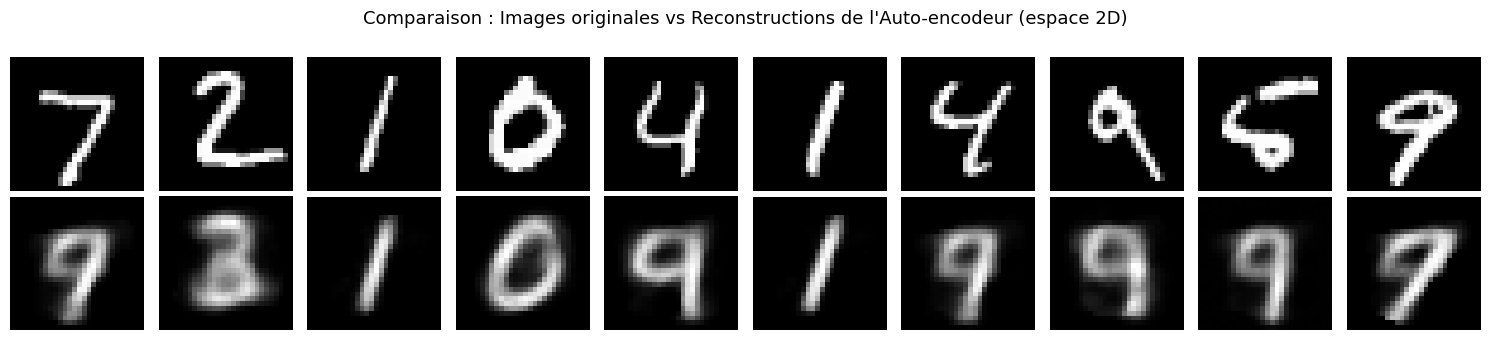

In [10]:
ae.eval()

x_sample, _ = next(iter(test_loader))
x_sample = x_sample[:10].to(device)

with torch.no_grad():
    x_hat = ae(x_sample)

fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))

for i in range(10):
    axes[0, i].imshow(x_sample[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12, labelpad=10)
axes[1, 0].set_ylabel("Reconstruit\n(AE simple)", fontsize=12, labelpad=10)

plt.suptitle("Comparaison : Images originales vs Reconstructions de l'Auto-encodeur (espace 2D)", fontsize=13)
plt.tight_layout()
plt.show()


### **Exploration 1 : Visualisation de l'Espace Latent 2D de l'Auto-encodeur**
Chaque image du test set est projetée par l'encodeur en un point $z = (z_1, z_2) \in \mathbb{R}^2$.
Visualisons ces points en les colorant selon le chiffre représenté.


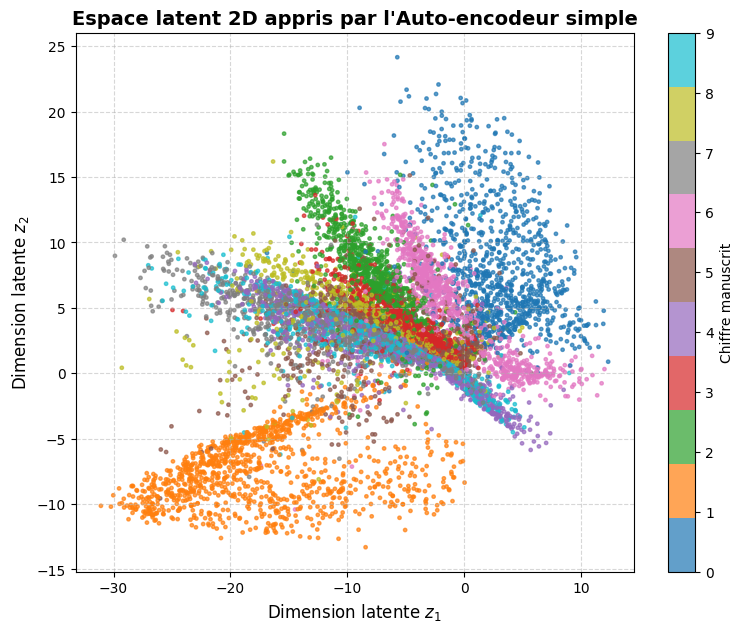

In [11]:
ae.eval()

zs = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        z = ae.encode(x)
        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(9, 7))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, cmap="tab10", s=6, alpha=0.7)
plt.colorbar(scatter, ticks=range(10), label="Chiffre manuscrit")
plt.xlabel("Dimension latente $z_1$", fontsize=12)
plt.ylabel("Dimension latente $z_2$", fontsize=12)
plt.title("Espace latent 2D appris par l'Auto-encodeur simple", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


### **Exploration 2 : Génération conditionnelle à partir d'un chiffre connu (Barycentre de classe)**
Puisque chaque chiffre se regroupe en un cluster dans l'espace latent, nous pouvons calculer le **vecteur moyen** $z_{\text{moyen}}$ pour chaque chiffre, puis le décoder pour synthétiser son prototype moyen.


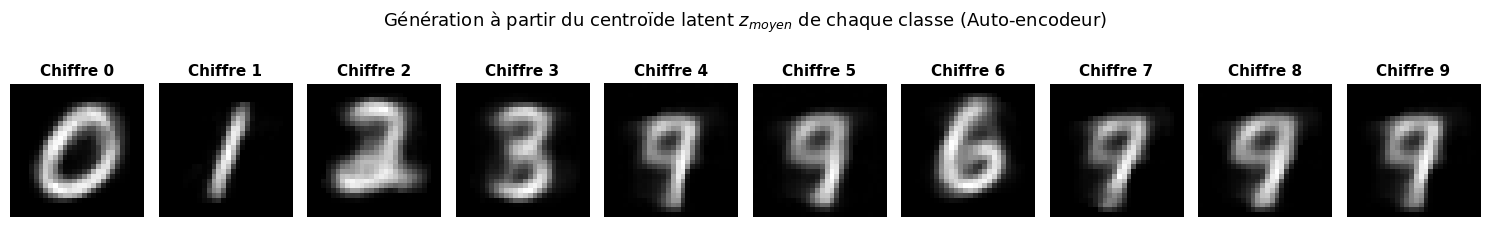

In [12]:
@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    if chiffre not in range(10):
        raise ValueError("Le chiffre doit être compris entre 0 et 9.")

    device = next(model.parameters()).device
    model.eval()

    somme_z = None
    nombre = 0

    for images, labels in dataloader:
        images = images[labels == chiffre]
        if images.shape[0] == 0:
            continue

        z = model.encode(images.to(device))

        if somme_z is None:
            somme_z = z.sum(dim=0, keepdim=True)
        else:
            somme_z += z.sum(dim=0, keepdim=True)

        nombre += z.shape[0]

    if nombre == 0:
        raise ValueError(f"Aucune image du chiffre {chiffre} trouvée.")

    z_moyen = somme_z / nombre
    return model.decode(z_moyen).cpu()

fig, axes = plt.subplots(1, 10, figsize=(15, 2.2))
for digit in range(10):
    img_gen = generer_chiffre(ae, train_loader, chiffre=digit)
    axes[digit].imshow(img_gen[0, 0].numpy(), cmap="gray")
    axes[digit].set_title(f"Chiffre {digit}", fontsize=11, fontweight="bold")
    axes[digit].axis("off")

plt.suptitle("Génération à partir du centroïde latent $z_{moyen}$ de chaque classe (Auto-encodeur)", fontsize=13, y=1.05)
plt.tight_layout()
plt.show()


### **Exploration 3 : Limites d'un Auto-encodeur Classique pour la Génération**
L'auto-encodeur classique présente des limites majeures pour la génération pure :
1. **Espace non régularisé :** Rien ne force l'espace latent à être continu, complet ou centré.
2. **Zones vides ("trous") :** Entre les clusters de chiffres, l'espace contient des zones où le décodeur n'a jamais été entraîné.
3. **Échec de l'échantillonnage aléatoire :** Si l'on tire un vecteur aléatoire $z \sim \mathcal{N}(0, I)$ et qu'on le décode, les images obtenues sont floues, déformées ou hybrides.

Vérifions cette limite ci-dessous :


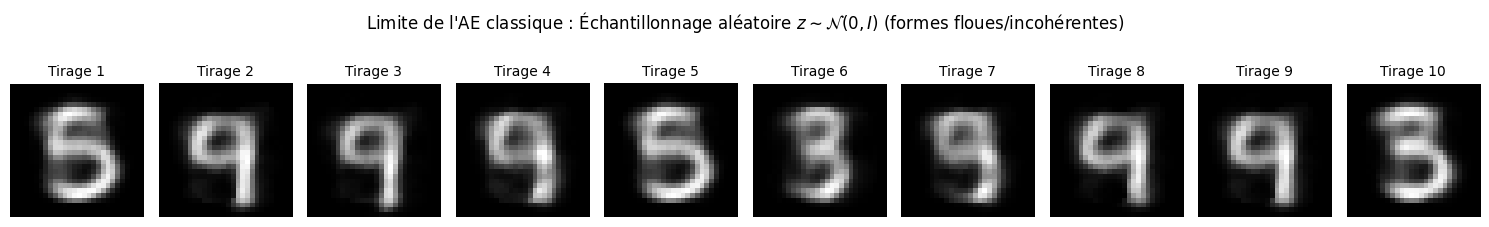

In [13]:
ae.eval()

with torch.no_grad():
    z_random = torch.randn(10, 2).to(device)
    samples_ae = ae.decode(z_random).cpu()

fig, axes = plt.subplots(1, 10, figsize=(15, 2.2))
for i, ax in enumerate(axes):
    ax.imshow(samples_ae[i].squeeze(), cmap="gray")
    ax.set_title(f"Tirage {i+1}", fontsize=10)
    ax.axis("off")

plt.suptitle("Limite de l'AE classique : Échantillonnage aléatoire $z \sim \mathcal{N}(0, I)$ (formes floues/incohérentes)", fontsize=12, y=1.05)
plt.tight_layout()
plt.show()


# **Partie 4 : Créer, Entraîner, Évaluer et Explorer un VAE (Variational Autoencoder)**

### **1. Principe théorique du VAE**
Pour résoudre les limites de l'auto-encodeur classique, le **Variational Autoencoder (VAE)** (Kingma & Welling, 2013) introduit une approche probabiliste :
- L'encodeur n'associe pas une entrée $x$ à un point fixe $z$, mais prédit les paramètres d'une distribution normale conditionnelle :
$$
q_\phi(z|x) = \mathcal{N}(\mu(x), \Sigma(x))
$$
où $\Sigma(x) = \text{diag}(\sigma^2(x))$.
- L'encodeur fournit deux sorties :
  - Le vecteur moyen $\mu \in \mathbb{R}^d$
  - Le vecteur de log-variance $\log(\sigma^2) \in \mathbb{R}^d$ (l'exponentielle garantit $\sigma^2 > 0$).

### **2. Le Reparameterization Trick**
Pour échantillonner $z \sim \mathcal{N}(\mu, \sigma^2)$ tout en permettant la rétropropagation du gradient, on extrait la stochasticité vers un bruit gaussien auxiliaire $\epsilon \sim \mathcal{N}(0, I)$ :
$$
z = \mu + \sigma \odot \epsilon \quad \text{avec} \quad \sigma = \exp\left(\frac{1}{2}\log\sigma^2\right)
$$

### **3. Fonction de perte du VAE : L'ELBO (Evidence Lower Bound)**
La perte minimise simultanément deux objectifs :
$$
\mathcal{L}_{\text{VAE}} = \mathcal{L}_{\text{reconstruction}} + \beta \cdot D_{\text{KL}}\left(q_\phi(z|x) \,\|\, p(z)\right)
$$
1. **Perte de reconstruction (Binary Cross Entropy) :**
   $$\mathcal{L}_{\text{rec}} = -\sum_{i=1}^{784} \left[ x_i \log(\hat{x}_i) + (1 - x_i)\log(1 - \hat{x}_i) \right]$$
   Assure que le décodeur reproduise fidèlement les pixels de l'image.
2. **Divergence de Kullback-Leibler ($D_{\text{KL}}$) :**
   Mesure l'écart entre $q_\phi(z|x)$ et l'a priori standard $p(z) \sim \mathcal{N}(0, I)$ :
   $$D_{\text{KL}} = -\frac{1}{2} \sum_{j=1}^d \left( 1 + \log(\sigma_j^2) - \mu_j^2 - \exp(\log(\sigma_j^2)) \right)$$
   Ce terme régularise l'espace latent en le rendant continu, complet et centré à l'origine $(0, 0)$.


In [14]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        # Encodeur : 784 -> 256 -> 64
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        # Deux branches parallèles pour mu et logvar
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        # Décodeur : latent_dim (2) -> 64 -> 256 -> 784 -> Sigmoid
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

vae = VAE(latent_dim=2).to(device)
print(vae)


VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### **Fonction de Perte et Entraînement du VAE**
Nous implémentons `vae_loss` avec réduction par somme et entraînons le VAE pendant 15 époques.


In [15]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(x_hat, x, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    total_loss = rec_loss + beta * kl_loss
    return total_loss, rec_loss, kl_loss

vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

def train_vae(model, loader, epochs=15, beta=1.0):
    model.train()
    history = {"loss": [], "rec": [], "kl": []}

    for epoch in range(epochs):
        total_loss = 0.0
        total_rec = 0.0
        total_kl = 0.0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)
            loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta=beta)

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)
        avg_loss = total_loss / n
        avg_rec = total_rec / n
        avg_kl = total_kl / n

        history["loss"].append(avg_loss)
        history["rec"].append(avg_rec)
        history["kl"].append(avg_kl)

        print(
            f"Époque [{epoch+1:02d}/{epochs}] | "
            f"Perte totale={avg_loss:.2f} | "
            f"Reconstruction={avg_rec:.2f} | "
            f"Divergence KL={avg_kl:.2f}"
        )

    return history

print("--- Début de l'entraînement du VAE ---")
vae_history = train_vae(vae, train_loader, epochs=15, beta=1.0)


--- Début de l'entraînement du VAE ---
Époque [01/15] | Perte totale=195.34 | Reconstruction=191.64 | Divergence KL=3.69
Époque [02/15] | Perte totale=166.78 | Reconstruction=161.84 | Divergence KL=4.94
Époque [03/15] | Perte totale=160.72 | Reconstruction=155.43 | Divergence KL=5.29
Époque [04/15] | Perte totale=157.18 | Reconstruction=151.67 | Divergence KL=5.51
Époque [05/15] | Perte totale=154.75 | Reconstruction=149.08 | Divergence KL=5.66
Époque [06/15] | Perte totale=152.95 | Reconstruction=147.18 | Divergence KL=5.77
Époque [07/15] | Perte totale=151.57 | Reconstruction=145.71 | Divergence KL=5.87
Époque [08/15] | Perte totale=150.51 | Reconstruction=144.58 | Divergence KL=5.93
Époque [09/15] | Perte totale=149.32 | Reconstruction=143.27 | Divergence KL=6.04
Époque [10/15] | Perte totale=148.35 | Reconstruction=142.24 | Divergence KL=6.11
Époque [11/15] | Perte totale=147.64 | Reconstruction=141.50 | Divergence KL=6.14
Époque [12/15] | Perte totale=146.92 | Reconstruction=140.7

### **Visualisation des Courbes d'Apprentissage du VAE**
Observons la dynamique de la perte totale, de la perte de reconstruction et de la divergence KL.


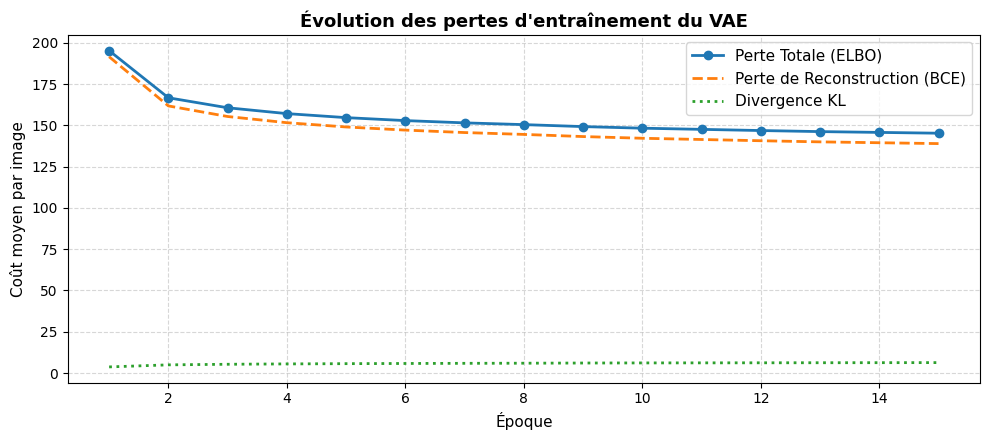

In [16]:
plt.figure(figsize=(10, 4.5))
epochs_range = range(1, len(vae_history["loss"]) + 1)
plt.plot(epochs_range, vae_history["loss"], label="Perte Totale (ELBO)", marker='o', linewidth=2)
plt.plot(epochs_range, vae_history["rec"], label="Perte de Reconstruction (BCE)", linestyle='--', linewidth=2)
plt.plot(epochs_range, vae_history["kl"], label="Divergence KL", linestyle=':', linewidth=2)
plt.xlabel("Époque", fontsize=11)
plt.ylabel("Coût moyen par image", fontsize=11)
plt.title("Évolution des pertes d'entraînement du VAE", fontsize=13, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### **Évaluation : Qualité de Reconstruction du VAE**
Comparons les images originales avec leurs reconstructions produites par le VAE.


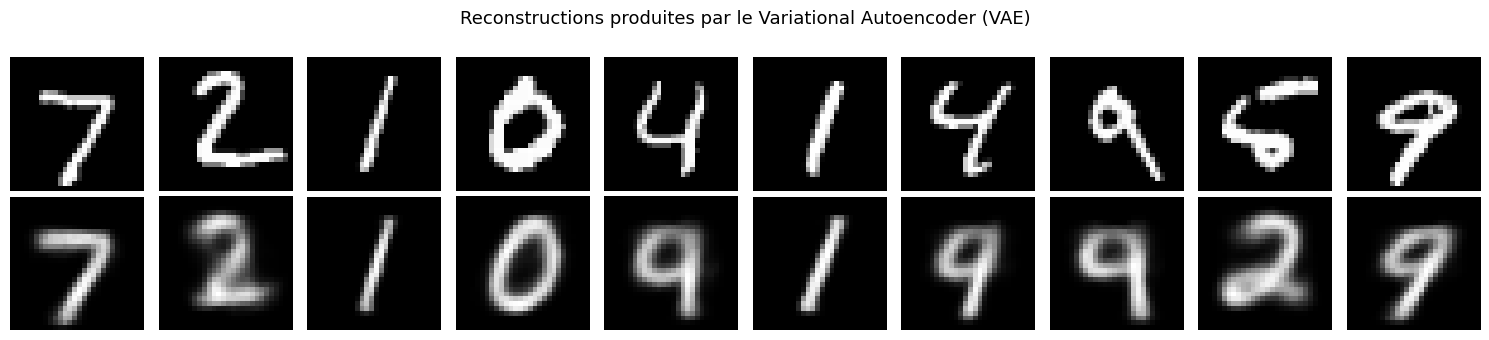

In [17]:
vae.eval()

with torch.no_grad():
    x_hat_vae, _, _ = vae(x_sample)

fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))

for i in range(10):
    axes[0, i].imshow(x_sample[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat_vae[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12, labelpad=10)
axes[1, 0].set_ylabel("Reconstruit\n(VAE)", fontsize=12, labelpad=10)

plt.suptitle("Reconstructions produites par le Variational Autoencoder (VAE)", fontsize=13)
plt.tight_layout()
plt.show()


### **Exploration 1 : Visualisation de l'Espace Latent Régularisé du VAE**
Nous projetons les moyennes latentes $\mu = (\mu_1, \mu_2)$ pour l'ensemble du jeu de test.
Contrairement à l'auto-encodeur classique :
- L'espace est centré en $(0, 0)$ avec une variance unitaire imposée par la divergence KL.
- La distribution globale est homogène sans discontinuités béantes.


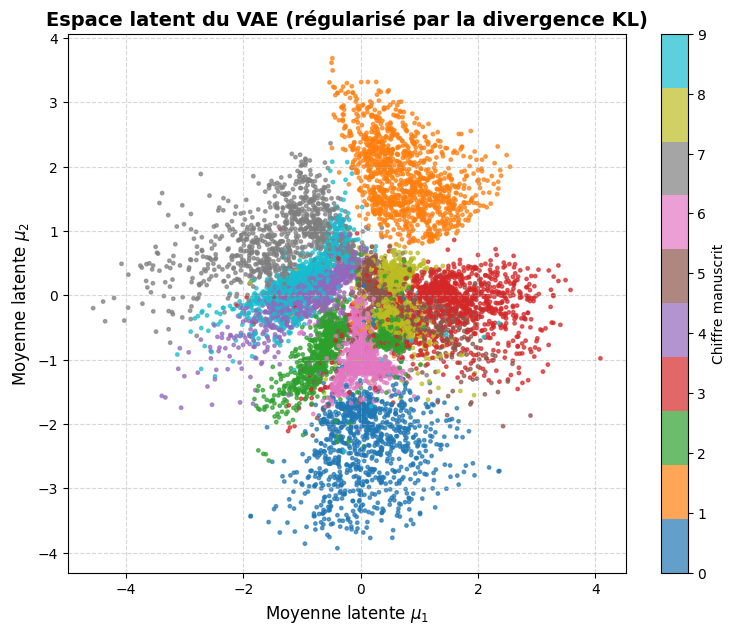

In [18]:
vae.eval()

mus = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        mu, logvar = vae.encode(x)
        mus.append(mu.cpu())
        ys.append(y)

MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(9, 7))
scatter = plt.scatter(MU[:, 0], MU[:, 1], c=Y, cmap="tab10", s=6, alpha=0.7)
plt.colorbar(scatter, ticks=range(10), label="Chiffre manuscrit")
plt.xlabel("Moyenne latente $\mu_1$", fontsize=12)
plt.ylabel("Moyenne latente $\mu_2$", fontsize=12)
plt.title("Espace latent du VAE (régularisé par la divergence KL)", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


### **Exploration 2 : Génération de Nouveaux Chiffres Ex Nihilo ($z \sim \mathcal{N}(0, I)$)**
Sans aucune image d'entrée, nous tirons 20 vecteurs aléatoires de la loi a priori standard $\mathcal{N}(0, I)$ et les transmettons directement au décodeur.


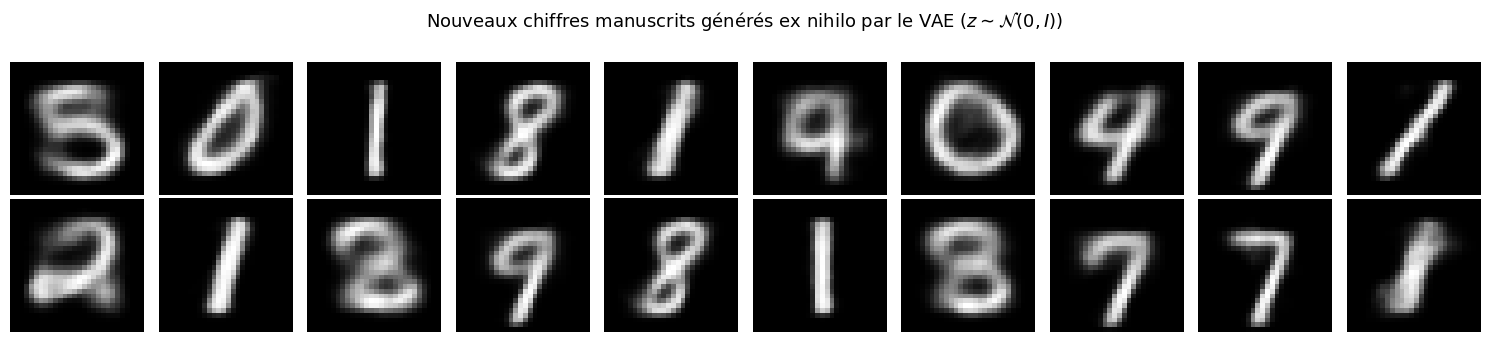

In [19]:
vae.eval()

with torch.no_grad():
    z_random = torch.randn(20, 2).to(device)
    new_digits = vae.decode(z_random).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))

for i, ax in enumerate(axes.flat):
    ax.imshow(new_digits[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("Nouveaux chiffres manuscrits générés ex nihilo par le VAE ($z \sim \mathcal{N}(0, I)$)", fontsize=13)
plt.tight_layout()
plt.show()


### **Exploration 3 : Exploration Continue de l'Espace Latent (Grille 2D Manifold)**
Nous construisons une grille régulière $15 \times 15$ sur l'intervalle $[-3, 3] \times [-3, 3]$.
Pour chaque position latente $(z_1, z_2)$, nous décodons l'image afin de visualiser la variété continue des chiffres et les transitions progressives.


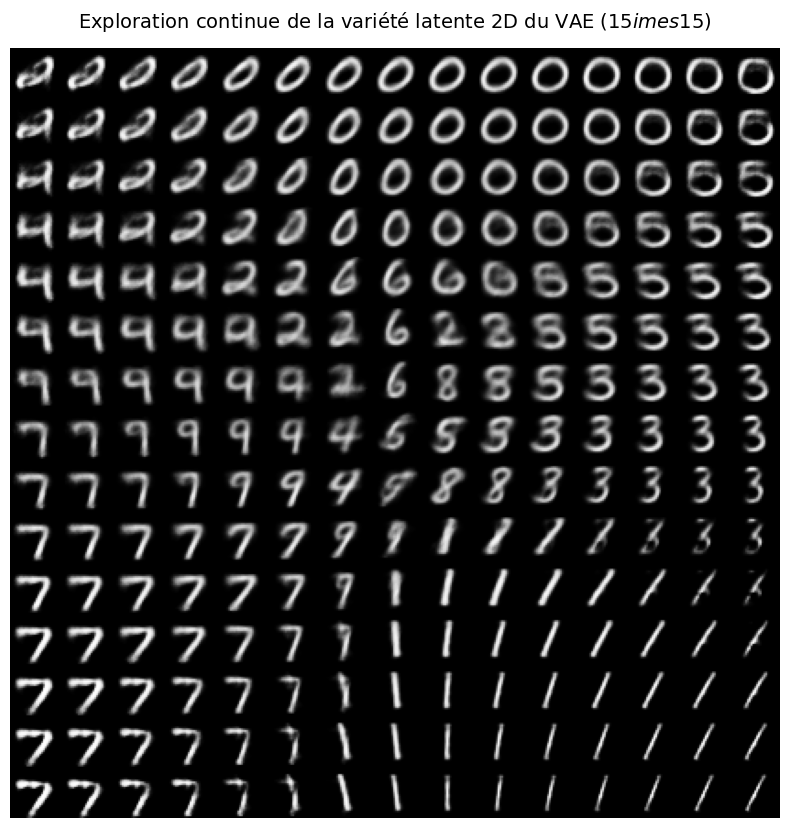

In [20]:
vae.eval()

grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(-3, 3, 15)

canvas = np.zeros((28 * 15, 28 * 15))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z = torch.tensor([[xi, yi]], dtype=torch.float32, device=device)
            x_hat = vae.decode(z)
            digit = x_hat.cpu().numpy()[0, 0]

            canvas[
                i * 28 : (i + 1) * 28,
                j * 28 : (j + 1) * 28
            ] = digit

plt.figure(figsize=(10, 10))
plt.imshow(canvas, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de la variété latente 2D du VAE ($15 \times 15$)", fontsize=14, pad=15)
plt.show()


### **Exploration 4 : Interpolation Linéaire Latente (Morphing entre deux chiffres)**
Nous sélectionnons deux chiffres distincts dans le jeu de test, encodons leurs moyennes latentes $z_A$ et $z_B$, puis effectuons une interpolation linéaire :
$$z(t) = (1 - t) \cdot z_A + t \cdot z_B \quad \text{pour } t \in [0, 1]$$
Le décodeur génère la transformation continue et fluide entre les deux chiffres.


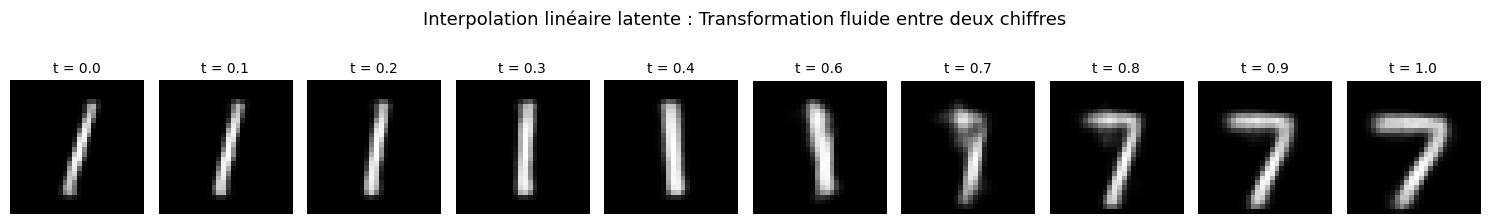

In [21]:
vae.eval()

img_A = x_sample[2:3]  # Premier chiffre
img_B = x_sample[0:1]  # Deuxième chiffre

with torch.no_grad():
    mu_A, _ = vae.encode(img_A)
    mu_B, _ = vae.encode(img_B)

    steps = 10
    alphas = np.linspace(0, 1, steps)
    interpolated_digits = []

    for alpha in alphas:
        z_interp = (1 - alpha) * mu_A + alpha * mu_B
        digit_interp = vae.decode(z_interp).cpu().squeeze()
        interpolated_digits.append(digit_interp)

fig, axes = plt.subplots(1, steps, figsize=(15, 2.2))
for idx, ax in enumerate(axes):
    ax.imshow(interpolated_digits[idx], cmap="gray")
    ax.set_title(f"t = {alphas[idx]:.1f}", fontsize=10)
    ax.axis("off")

plt.suptitle("Interpolation linéaire latente : Transformation fluide entre deux chiffres", fontsize=13, y=1.05)
plt.tight_layout()
plt.show()


# **5. Synthèse Comparative Finale**

Le tableau ci-dessous résume les distinctions fondamentales entre les trois paradigmes étudiés dans ce TP :

| Propriété / Critère | Modèle Discriminatif (MLP) | Auto-encodeur Simple (AE) | Variational Autoencoder (VAE) |
| :--- | :--- | :--- | :--- |
| **Objectif principal** | Classifier : estimer $P(y\|x)$ | Compresser et reconstruire : $\hat{x} \approx x$ | Modéliser la distribution des données : $P(x)$ |
| **Type d'apprentissage** | Supervisé (nécessite les labels $y$) | Non supervisé (sans labels) | Non supervisé probabiliste (sans labels) |
| **Espace latent** | Aucun (couches cachées non contraintes) | Déterministe ($z = f(x)$), discontinu avec zones vides | Probabiliste ($z \sim \mathcal{N}(\mu, \sigma^2)$), continu et centré en $0$ |
| **Fonction de perte** | Cross-Entropy Loss | Mean Squared Error (MSE) | ELBO = Reconstruction (BCE) + Divergence KL |
| **Génération ex nihilo ($z \sim \mathcal{N}(0, I)$)** | ❌ Impossible | ❌ Formes floues / incohérentes | ✅ Chiffres nets, variés et réalistes |
| **Interpolation fluide** | ❌ Non applicable | ⚠️ Mauvaise (artefacts dans les zones vides) | ✅ Transition morphologique continue |

### **Conclusion Générale**
1. **Modèle Discriminatif :** Parfaitement adapté pour prédire une classe ($>97\%$ d'accuracy), mais incapable de créer ou d'extrapoler de nouvelles observations.
2. **Auto-encodeur Simple :** Excellent compresseur de données, mais son espace latent non régularisé rend l'échantillonnage aléatoire inefficace.
3. **Variational Autoencoder (VAE) :** Grâce au formalisme bayésien, au *reparameterization trick* et au terme de divergence KL, le VAE structure l'espace latent en une variété continue et compacte, faisant de lui un **véritable modèle génératif probabiliste**.
